In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [53]:
amz=pd.read_csv('C:/Users/jesus/Downloads/archive (2)/amz_uk_price_prediction_dataset.csv')
amz.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


The top 5 cathegories are:

In [11]:
amz['category'].value_counts().head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

2.- Visualizations:

The biggest cathegory is Sports & Outdoors.

<Axes: ylabel='category'>

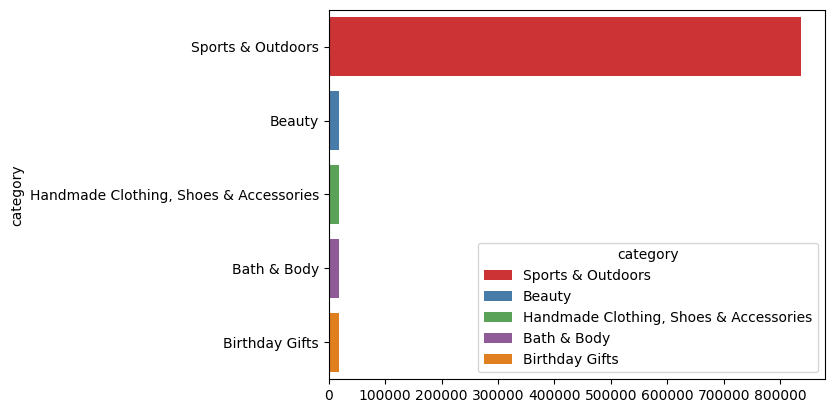

In [52]:
# top_5_cat= amz['category'].value_counts()
top_5_cat= amz['category'].value_counts().head(5)

sns.barplot(y=top_5_cat.index,x=top_5_cat.values,palette="Set1", hue=top_5_cat.index, legend=True )

<Axes: ylabel='count'>

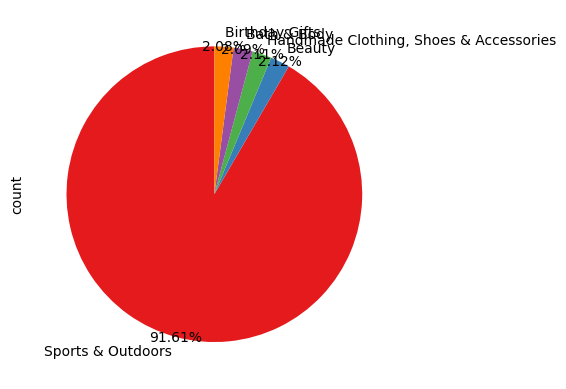

In [50]:
# plt.figure(figsize=(10, 8))
top_5_cat.plot.pie(autopct='%.2f%%', startangle=90, colors=sns.color_palette("Set1"),pctdistance=1)

## Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

# 1.Measures of Centrality:

Calculate the mean, median, and mode for the price of products.

What's the average price point of products listed? How does this compare with the most common price point (mode)?

The avergae price is: 19.09. It is 10 dollars more expensive than the most commom price.

In [63]:
mean_price=amz['price'].mean()
median_price=amz['price'].median()
mode_price=amz['price'].mode()

display("Mean", mean_price) #El que está a la mitad de la lista de precios
display("Mode", mode_price) #el precio que más se repite
display("Median",median_price) #The average
display("Max, price",amz['price'].max())
display("Min price",amz['price'].min())

'Mean'

np.float64(89.24380943923663)

'Mode'

0    9.99
Name: price, dtype: float64

'Median'

np.float64(19.09)

'Max, price'

np.float64(100000.0)

'Min price'

np.float64(0.0)

In [78]:
titles_with_zero_price = amz[amz["price"] == 0][['title','category', 'price']]
titles_with_zero_price['category'].value_counts()

category
Sports & Outdoors                  5
Games & Game Accessories           4
PC & Video Games                   3
Piano & Keyboard                   2
School & Educational Supplies      1
Radio Communication                1
Health & Personal Care             1
Toy Advent Calendars               1
Professional Education Supplies    1
Sports Supplements                 1
Name: count, dtype: int64

## 2 Measures of Dispersion:

Determine the variance, standard deviation, range, and interquartile range for product price.

How varied are the product prices? Are there any indicators of a significant spread in prices?

The prices are highly varied as shown by the variance. From the point of view of the range, for example, there's a difference of 100.000 between the cheapest (0.00) and the most expensive item (100.000). From the point of view of the STD of $345.61 when the quantiles are 9.99, 19.09 and 45.99 can only suggest that individual products are deviated from the avergae prices mainly caused by products with high prices that are affecting the mean and the STD directly.

In [84]:
variance_price = amz['price'].var()
std_dev_price = amz['price'].std()
range_price = amz['price'].max() - amz['price'].min()
quantiles_price = amz['price'].quantile([0.25, 0.5, 0.75])

display(variance_price, std_dev_price, range_price, quantiles_price)

np.float64(119445.48532254907)

np.float64(345.60886175349884)

np.float64(100000.0)

0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64

<Axes: xlabel='price'>

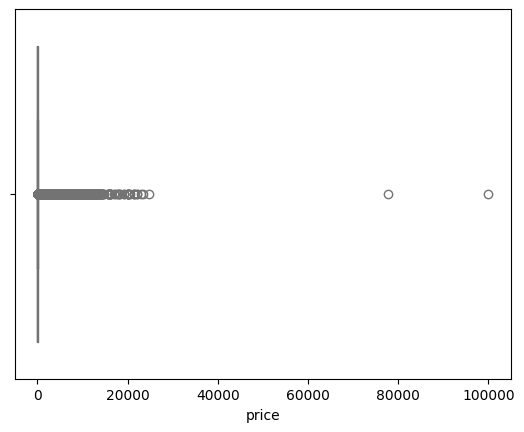

In [81]:
sns.boxplot(x = amz['price'], color="lightgreen")

## 3 Visualizations:

Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved.

Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.


Most products are between 9.00 and 19.00 based on previous analysis. The histogram graph is hard to read because of the Kurtosis peak confirming the presence of outliers also due to the presence of 2,115,963 products (86.60%) with a price under 100 dollar.

In [115]:
under_100=((amz['price']<100).sum()*100)/amz['price'].count()
under_100

np.float64(86.59022912846393)

<Axes: xlabel='price', ylabel='Count'>

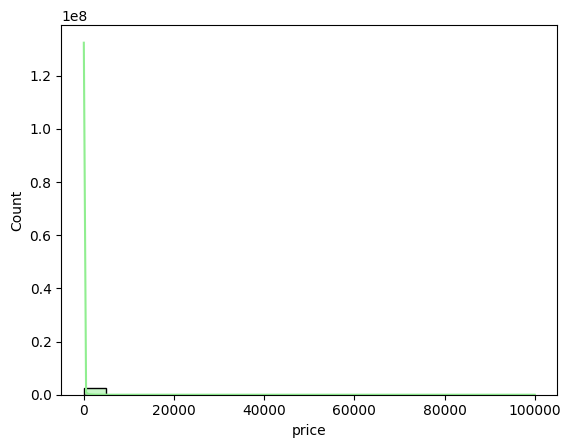

In [102]:
sns.histplot(amz['price'], kde=True, bins=20, color="Lightgreen")

<Axes: xlabel='price'>

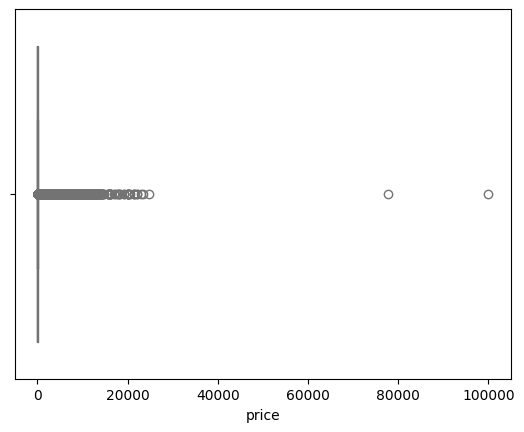

In [98]:
sns.boxplot(x = amz['price'], color="lightgreen")

## Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?


After filtering the data to obtain only rated products I can see that there's a tendency to high rates in the rated products with 4.5 as the mode and an average of 4.4.

In [122]:
rated=amz[amz['stars']>0]
rated

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443642,2828585,B07DCFQMQL,Speed MaxX BODY ARMOUR CE MOTORBIKE/MOTORCYCLE...,3.6,66,49.99,False,0,Motorbike Clothing
2443643,2828586,B07JM5VQFX,Motorcycle Clothing Suit - Motorbike Suit With...,4.1,5,158.99,False,0,Motorbike Clothing
2443644,2828587,B07X98JLFF,GREAT BIKERS GEAR - Bobber Cafe Brat Style Lea...,3.6,12,14.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [128]:
mean_price=rated['stars'].mean()
median_price=rated['stars'].median()
mode_price=rated['stars'].mode()

display("Mean", mean_price) #El que está a la mitad de la lista de precios
display("Mode", mode_price) #el precio que más se repite
display("Median",median_price) #The average

'Mean'

np.float64(4.31916076222691)

'Mode'

0    4.5
Name: stars, dtype: float64

'Median'

np.float64(4.4)

# Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

There's no wide deviation in the feedback from the customers. The STD, variance and quantiles demosntrate this. Even thoguh the range is high this only shows that there are low rated items and high rated items in the DF.

In [131]:
variance_stars = rated['stars'].var()
std_dev_stars = rated['stars'].std()
range_stars = rated['stars'].max() - rated['stars'].min()
quantiles_stars = rated['stars'].quantile([0.25, 0.5, 0.75])

display(variance_stars, std_dev_stars, range_stars, quantiles_stars)

np.float64(0.30834337523872835)

np.float64(0.5552867504620729)

np.float64(4.0)

0.25    4.1
0.50    4.4
0.75    4.6
Name: stars, dtype: float64

# Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?

Based on the Skewness being negative we can say that there's a tendency to higher values as the tail will be on the left of the chart. HAving a high Kurtosis also confirms that the majority of the ratings are concentrated around the mean of 4.3.

In [132]:
skewness_stars = rated['stars'].skew()
kurtosis_stars = rated['stars'].kurtosis()

skewness_stars, kurtosis_stars

(np.float64(-2.3795681122127945), np.float64(9.78193769066435))

# Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

<Axes: xlabel='stars', ylabel='Count'>

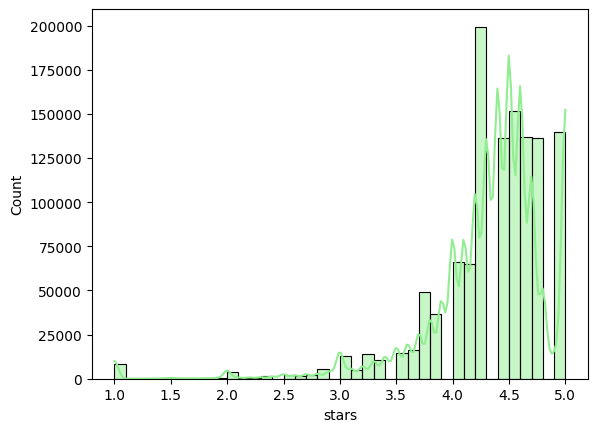

In [136]:
sns.histplot(rated['stars'], kde=True, bins=40, color="Lightgreen")